# Level 2 — Logistic Regression: Full ML Pipeline

**Goal:** predict `good_lunch` (1 = good, 0 = not good) from four recorded lunch features.

This notebook implements logistic regression and batch gradient descent **from scratch**.

## 1. Imports and reproducibility

We use a fixed random seed. The split is stratified manually: 80% of each class goes to training and 20% to testing, so class proportions remain similar.

In [1]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_SEED = 42
TEST_FRACTION = 0.20

candidate_path = [
    Path("binary_classification.csv"),
]
DATA_PATH = next((p for p in candidate_path if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "Place binary_classification.csv beside this notebook or in datasets/."
    )

df = pd.read_csv(DATA_PATH)
print("Loaded:", DATA_PATH, "| Shape:", df.shape)
display(df.head())

Loaded: binary_classification.csv | Shape: (500, 5)


,queue_length,plate_waste_fraction,menu_board_kcal,handwriting_neatness,good_lunch
0,43,0.575,2096,8.2,0
1,37,0.497,1924,5.2,0
2,43,0.348,2280,7.7,1
3,35,0.812,2015,4.8,0
4,28,0.377,2492,9.2,0


## 2. Inspecting the dataset

The inputs are `queue_length`, `plate_waste_fraction`, `menu_board_kcal`, and `handwriting_neatness`. The target `good_lunch` is binary: 1 or 0.

Check data types, missing values, class balance, and summary statistics before training.

In [2]:
TARGET = "good_lunch"
FEATURES = [
    "queue_length",
    "plate_waste_fraction",
    "menu_board_kcal",
    "handwriting_neatness",
]
required = FEATURES + [TARGET]

missing_columns = [c for c in required if c not in df.columns]
if missing_columns:
    raise ValueError(f"Missing expected columns: {missing_columns}")
if df[required].isna().any().any():
    raise ValueError("Missing values found; choose an imputation strategy before training.")
if not set(df[TARGET].unique()).issubset({0, 1}):
    raise ValueError("good_lunch must contain only 0 and 1.")

print("Data types:")
display(df[required].dtypes.to_frame("dtype"))
print("\nMissing values:")
display(df[required].isna().sum().to_frame("missing_count"))
print("\nClass counts:")
display(df[TARGET].value_counts().sort_index().rename(index={0: "Not good (0)", 1: "Good (1)"}).to_frame("count"))
print("\nSummary statistics:")
display(df[required].describe().T)

Data types:


,dtype
queue_length,int64
plate_waste_fraction,float64
menu_board_kcal,int64
handwriting_neatness,float64
good_lunch,int64



Missing values:


,missing_count
queue_length,0
plate_waste_fraction,0
menu_board_kcal,0
handwriting_neatness,0
good_lunch,0



Class counts:


,count
good_lunch,
Not good (0),296
Good (1),204



Summary statistics:


,count,mean,std,min,25%,50%,75%,max
queue_length,500.0,36.894000,16.607419,0.0,25.0000,36.500,49.000,84.0
plate_waste_fraction,500.0,0.466914,0.213986,0.0,0.3185,0.476,0.604,1.0
menu_board_kcal,500.0,2046.626000,365.336310,893.0,1823.7500,2043.000,2290.750,3169.0
handwriting_neatness,500.0,5.148200,1.975211,1.0,3.7750,5.100,6.500,10.0
good_lunch,500.0,0.408000,0.491955,0.0,0.0000,0.000,1.000,1.0


## 3. Fixed-seed train/test split

The test set stays unseen during training. We split each class separately, shuffle with a fixed random generator, and combine the indices.

In [3]:
rng = np.random.default_rng(RANDOM_SEED)
train_indices, test_indices = [], []
y_all = df[TARGET].to_numpy(dtype=float)

for class_label in (0, 1):
    class_indices = np.flatnonzero(y_all == class_label)
    rng.shuffle(class_indices)
    n_test = int(round(TEST_FRACTION * len(class_indices)))
    test_indices.extend(class_indices[:n_test])
    train_indices.extend(class_indices[n_test:])

train_indices = np.array(train_indices, dtype=int)
test_indices = np.array(test_indices, dtype=int)
rng.shuffle(train_indices)
rng.shuffle(test_indices)

train_df = df.iloc[train_indices].reset_index(drop=True)
test_df = df.iloc[test_indices].reset_index(drop=True)

X_train_raw = train_df[FEATURES].to_numpy(dtype=float)
X_test_raw = test_df[FEATURES].to_numpy(dtype=float)
y_train = train_df[TARGET].to_numpy(dtype=float)
y_test = test_df[TARGET].to_numpy(dtype=float)

print(f"Training rows: {len(train_df)}")
print(f"Test rows: {len(test_df)}")
print("\nTraining class proportions:")
print(train_df[TARGET].value_counts(normalize=True).sort_index())
print("\nTest class proportions:")
print(test_df[TARGET].value_counts(normalize=True).sort_index())

Training rows: 400
Test rows: 100

Training class proportions:
good_lunch
0    0.5925
1    0.4075
Name: proportion, dtype: float64

Test class proportions:
good_lunch
0    0.59
1    0.41
Name: proportion, dtype: float64


## 4. Standardize features without data leakage

The four features have different units and numerical ranges. Standardization puts them on comparable scales:

\[x_{scaled} = \frac{x-\mu_{train}}{\sigma_{train}}\]

Calculate the mean and standard deviation using **training data only**, then apply those same values to the test set.

In [4]:
feature_means = X_train_raw.mean(axis=0)
feature_stds = X_train_raw.std(axis=0, ddof=0)
feature_stds[feature_stds == 0] = 1.0

X_train_scaled = (X_train_raw - feature_means) / feature_stds
X_test_scaled = (X_test_raw - feature_means) / feature_stds

display(pd.DataFrame({
    "feature": FEATURES,
    "training_mean": feature_means,
    "training_std": feature_stds,
}))
print("Scaled training means:", X_train_scaled.mean(axis=0))
print("Scaled training stds:", X_train_scaled.std(axis=0))

,feature,training_mean,training_std
0,queue_length,37.145000,16.982461
1,plate_waste_fraction,0.468585,0.211434
2,menu_board_kcal,2044.165000,364.882855
3,handwriting_neatness,5.107500,1.939406


Scaled training means: [-1.77635684e-16  1.15463195e-16  9.76996262e-17  5.10702591e-17]
Scaled training stds: [1. 1. 1. 1.]


## 5. Logistic regression and sigmoid

The model first forms a weighted sum:

\[z=w_1x_1+w_2x_2+\cdots+w_dx_d+b\]

Sigmoid maps the score to a value between 0 and 1:

\[\hat p=\sigma(z)=\frac{1}{1+e^{-z}}\]

We interpret this as the estimated probability of `good_lunch = 1`. At a threshold of 0.5, probabilities at least 0.5 become class 1.

In [5]:
def sigmoid(z):
    # Numerically stable sigmoid for NumPy arrays.
    z = np.asarray(z, dtype=float)
    result = np.empty_like(z)
    positive = z >= 0
    result[positive] = 1.0 / (1.0 + np.exp(-z[positive]))
    exp_z = np.exp(z[~positive])
    result[~positive] = exp_z / (1.0 + exp_z)
    return result

def predict_proba(X, weights, bias):
    return sigmoid(X @ weights + bias)

def predict_class(X, weights, bias, threshold=0.5):
    return (predict_proba(X, weights, bias) >= threshold).astype(int)

## 6. Binary cross-entropy loss

Binary cross-entropy measures how wrong the probabilities are:

\[L=-\frac{1}{m}\sum_{i=1}^{m}[y_i\log(\hat p_i)+(1-y_i)\log(1-\hat p_i)]\]

A confident correct prediction gets a small loss; a confident wrong prediction gets a large loss. We use an equivalent stable formula based on logits to avoid numerical problems near probabilities 0 and 1.

In [6]:
def binary_cross_entropy_from_logits(X, y, weights, bias):
    logits = X @ weights + bias
    return float(np.mean(np.logaddexp(0.0, logits) - y * logits))

zero_weights = np.zeros(X_train_scaled.shape[1])
print("Initial loss with zero weights:",
      binary_cross_entropy_from_logits(X_train_scaled, y_train, zero_weights, 0.0))

Initial loss with zero weights: 0.6931471805599452


## 7. Gradient descent — implemented manually

For batch logistic regression with binary cross-entropy:

\[\frac{\partial L}{\partial w}=\frac{1}{m}X^T(\hat p-y)\]

\[\frac{\partial L}{\partial b}=\frac{1}{m}\sum_{i=1}^{m}(\hat p_i-y_i)\]

Update the parameters by moving against the gradient:

\[w\leftarrow w-\alpha\frac{\partial L}{\partial w},\qquad b\leftarrow b-\alpha\frac{\partial L}{\partial b}\]

**Convergence criterion:** stop when the absolute change in training loss is below `TOLERANCE` for `PATIENCE` consecutive iterations. If the maximum iteration count is reached first, the run is marked as not converged.

In [7]:
TOLERANCE = 1e-8
PATIENCE = 20
MAX_ITERATIONS = 50_000

def train_logistic_regression(
    X, y, learning_rate,
    tolerance=TOLERANCE,
    patience=PATIENCE,
    max_iterations=MAX_ITERATIONS,
):
    n_samples, n_features = X.shape
    weights = np.zeros(n_features, dtype=float)
    bias = 0.0
    loss_history = []
    stable_steps = 0
    previous_loss = None
    converged = False

    start_time = time.perf_counter()

    for iteration in range(1, max_iterations + 1):
        probabilities = predict_proba(X, weights, bias)
        errors = probabilities - y

        # Batch gradients.
        dw = (X.T @ errors) / n_samples
        db = np.mean(errors)

        # Gradient-descent update.
        weights -= learning_rate * dw
        bias -= learning_rate * db

        current_loss = binary_cross_entropy_from_logits(X, y, weights, bias)
        loss_history.append(current_loss)

        if previous_loss is not None and abs(previous_loss - current_loss) < tolerance:
            stable_steps += 1
        else:
            stable_steps = 0

        if stable_steps >= patience:
            converged = True
            break

        previous_loss = current_loss

    elapsed_seconds = time.perf_counter() - start_time
    return {
        "weights": weights,
        "bias": bias,
        "loss_history": np.array(loss_history),
        "iterations": iteration,
        "converged": converged,
        "elapsed_seconds": elapsed_seconds,
        "learning_rate": learning_rate,
    }

## 8. Learning-rate hypotheses — written before the experiment

Various learning rate predictions:

- **0.001:** likely very slow but stable; may need many iterations.
- **0.01:** likely a steadier and faster loss decrease than 0.001.
- **0.1:** likely the fastest stable decrease because the features are standardized; if too large, it may overshoot or oscillate.

In [8]:
LEARNING_RATES = [0.001, 0.01, 0.1]
results = {}

for lr in LEARNING_RATES:
    results[lr] = train_logistic_regression(
        X_train_scaled, y_train, learning_rate=lr
    )

summary = pd.DataFrame([
    {
        "learning_rate": lr,
        "iterations": r["iterations"],
        "converged": r["converged"],
        "training_time_seconds": r["elapsed_seconds"],
        "final_training_loss": r["loss_history"][-1],
    }
    for lr, r in results.items()
])
display(summary)

,learning_rate,iterations,converged,training_time_seconds,final_training_loss
0,0.001,49933,True,1.956061,0.409773
1,0.010,6950,True,0.226323,0.409697
2,0.100,908,True,0.029433,0.409689


## 9. Plotting the loss curves

The y-axis is training binary cross-entropy. A downward curve indicates that the model is reducing training loss. Curves can have different lengths because the learning rates may converge at different iterations.

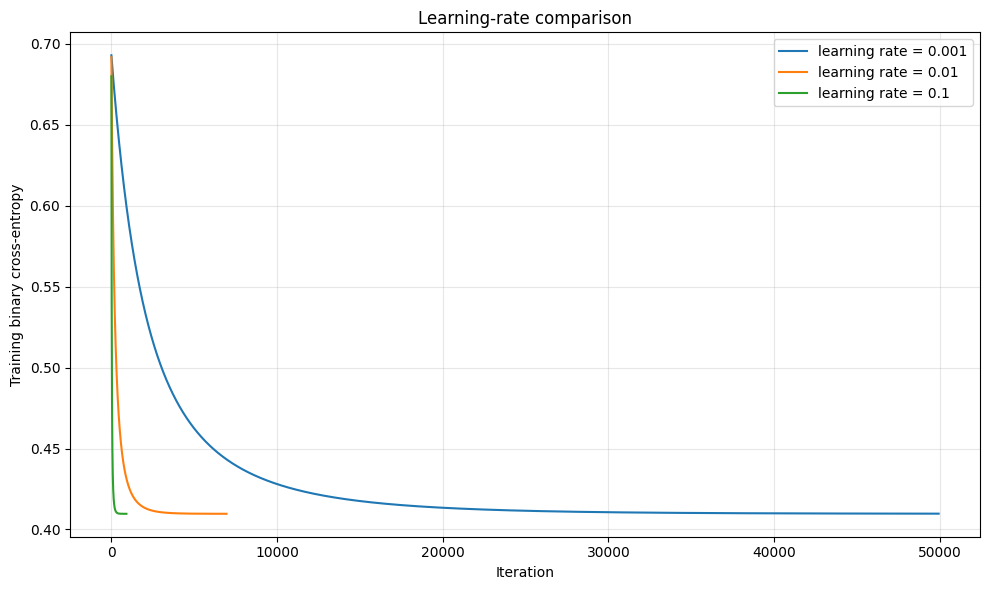

In [9]:
plt.figure(figsize=(10, 6))
for lr, result in results.items():
    plt.plot(
        np.arange(1, len(result["loss_history"]) + 1),
        result["loss_history"],
        label=f"learning rate = {lr}",
    )
plt.xlabel("Iteration")
plt.ylabel("Training binary cross-entropy")
plt.title("Learning-rate comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 10. Comparing the observations with the predictions

In [10]:
for lr, r in results.items():
    status = "converged" if r["converged"] else "hit iteration limit"
    print(
        f"lr={lr}: {status} after {r['iterations']} iterations; "
        f"final loss={r['loss_history'][-1]:.6f}"
    )

lr=0.001: converged after 49933 iterations; final loss=0.409773
lr=0.01: converged after 6950 iterations; final loss=0.409697
lr=0.1: converged after 908 iterations; final loss=0.409689


## 11. Held-out test evaluation

Use the model trained with learning rate 0.1 as the selected model. We evaluate it on the held-out test rows; the test data is not used for gradient updates.

Accuracy is the proportion of test examples classified correctly.

In [11]:
SELECTED_LR = 0.1
selected = results[SELECTED_LR]

test_probabilities = predict_proba(
    X_test_scaled, selected["weights"], selected["bias"]
)
test_predictions = (test_probabilities >= 0.5).astype(int)
test_accuracy = float(np.mean(test_predictions == y_test))

print(f"Selected learning rate: {SELECTED_LR}")
print(f"Test accuracy: {test_accuracy:.3f} ({test_accuracy:.1%})")
print(f"Converged: {selected['converged']}")
print(f"Iterations: {selected['iterations']}")
print(f"Training time: {selected['elapsed_seconds']:.6f} seconds")

Selected learning rate: 0.1
Test accuracy: 0.850 (85.0%)
Converged: True
Iterations: 908
Training time: 0.029433 seconds


## 12. Error analysis

In [12]:
error_positions = np.flatnonzero(test_predictions != y_test)
if len(error_positions) < 3:
    raise RuntimeError("Fewer than three test errors; cannot show three examples.")

error_table = test_df.iloc[error_positions][FEATURES].copy()
error_table["actual"] = y_test[error_positions].astype(int)
error_table["predicted_probability"] = test_probabilities[error_positions]
error_table["predicted"] = test_predictions[error_positions]
error_table["distance_from_threshold"] = np.abs(
    test_probabilities[error_positions] - 0.5
)

three_errors = (
    error_table.sort_values("distance_from_threshold")
    .head(3)
    .drop(columns="distance_from_threshold")
)
display(three_errors)
print(f"Total test errors: {len(error_positions)} / {len(y_test)}")

,queue_length,plate_waste_fraction,menu_board_kcal,handwriting_neatness,actual,predicted_probability,predicted
28,42,0.420,1867,4.0,1,0.470161,0
73,41,0.485,2103,6.5,1,0.450894,0
72,48,0.647,2162,6.0,1,0.410574,0


Total test errors: 15 / 100


3 of the errors have similar/high queue length values. One hypothesis is that the model gave a high weight value for queue length feature. So, a high queue length value would influence the model to predict that it was a bad lunch, irrespective of the other parameters. 

### Hypothesis and test: does handwriting neatness help?

**Hypothesis:** `handwriting_neatness` may contribute little predictive information. A simple correlation check suggests its relationship with the target is weak. Removing it may leave accuracy unchanged or slightly improve it.

**Test:** removing only this feature, recalculate scaling statistics from the same training rows, retrain with the same learning rate, and evaluate on the same test rows.

In [13]:
reduced_features = [f for f in FEATURES if f != "handwriting_neatness"]
X_train_reduced_raw = train_df[reduced_features].to_numpy(dtype=float)
X_test_reduced_raw = test_df[reduced_features].to_numpy(dtype=float)

reduced_means = X_train_reduced_raw.mean(axis=0)
reduced_stds = X_train_reduced_raw.std(axis=0)
reduced_stds[reduced_stds == 0] = 1.0

X_train_reduced = (X_train_reduced_raw - reduced_means) / reduced_stds
X_test_reduced = (X_test_reduced_raw - reduced_means) / reduced_stds

reduced_result = train_logistic_regression(
    X_train_reduced, y_train, learning_rate=SELECTED_LR
)
reduced_predictions = predict_class(
    X_test_reduced, reduced_result["weights"], reduced_result["bias"]
)
reduced_accuracy = float(np.mean(reduced_predictions == y_test))

comparison = pd.DataFrame([
    {
        "experiment": "All four features",
        "test_accuracy": test_accuracy,
        "test_errors": int(np.sum(test_predictions != y_test)),
    },
    {
        "experiment": "Drop handwriting_neatness",
        "test_accuracy": reduced_accuracy,
        "test_errors": int(np.sum(reduced_predictions != y_test)),
    },
])
display(comparison)
print(f"Accuracy change: {reduced_accuracy - test_accuracy:+.3f}")

,experiment,test_accuracy,test_errors
0,All four features,0.85,15
1,Drop handwriting_neatness,0.85,15


Accuracy change: +0.000


Thus, droppiong the 'handwriting_neatness' did not improve the accuracy.  
One hypothesis is that its corresponding weight was very small thus not having much influence on the predictions. (unlike queue length as a feature)